# Boltzmann wealth model

100 agents start with 1 unit of wealth each. Each step, every agent with wealth gives 1 unit to an agent chosen at random. Total wealth never changes, yet inequality appears. Inequality is measured with the Gini coefficient. Slides 15–19.

*Made for this site, following the rules on the slides (`1 Lecture/Agent Based Modelling with Mesa - Slides.html`). It uses Mesa 3 (`mesa.discrete_space`), tested with Mesa 3.5.1 in the browser. The interactive Solara versions on py.cafe, linked from the slides, need the internet and run outside this site.*

In [ ]:
# Run this cell first.
# In the browser (JupyterLite) it installs the extra packages into this tab;
# in Colab or Anaconda it installs them with pip (already installed = no change).
%pip install mesa networkx

In [2]:
import mesa
import numpy as np
import matplotlib.pyplot as plt

**Gini coefficient.** With wealths sorted from smallest to largest (w₁ ≤ … ≤ wₙ, i = 1…n):

G = 2 Σ i·wᵢ / (n Σ wᵢ) − (n + 1)/n

G = 0 means everyone has the same. The largest possible value is (n − 1)/n (one agent has everything), which is close to 1 for large n.

In [3]:
def gini(w):
    w = np.sort(np.asarray(w, dtype=float)); n = len(w); i = np.arange(1, n + 1)
    return 2 * np.sum(i * w) / (n * np.sum(w)) - (n + 1) / n


class MoneyAgent(mesa.Agent):
    def __init__(self, model):
        super().__init__(model)
        self.wealth = 1

    def step(self):
        if self.wealth > 0:
            other = self.random.choice(self.model.agents)
            other.wealth += 1
            self.wealth -= 1


class BoltzmannWealth(mesa.Model):
    def __init__(self, n=100, seed=1):
        super().__init__(rng=seed)
        MoneyAgent.create_agents(self, n)

    def step(self):
        self.agents.shuffle_do("step")

    def wealths(self):
        return [a.wealth for a in self.agents]

**Run 300 steps.** Predict first: does random exchange keep wealth equal?

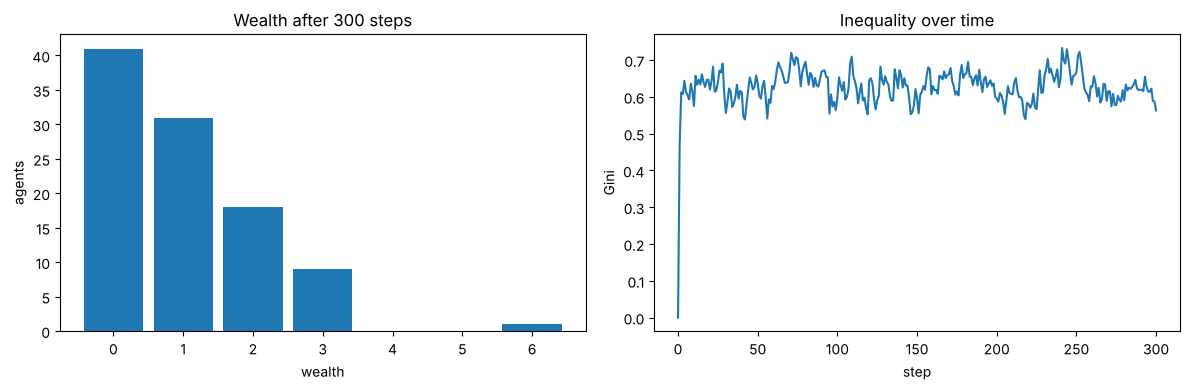

Total wealth 100 (unchanged), Gini 0.00 at the start and 0.62 on average over the last 50 steps


In [4]:
model = BoltzmannWealth()
g = [gini(model.wealths())]
for _ in range(300):
    model.step(); g.append(gini(model.wealths()))

w = model.wealths()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(w, bins=range(0, max(w) + 2), align="left", rwidth=0.85); axes[0].set(xlabel="wealth", ylabel="agents", title="Wealth after 300 steps")
axes[1].plot(g); axes[1].set(xlabel="step", ylabel="Gini", title="Inequality over time")
plt.tight_layout(); plt.show()
print(f"Total wealth {sum(w)} (unchanged), Gini {g[0]:.2f} at the start and {np.mean(g[-50:]):.2f} on average over the last 50 steps")